# Week 01: Machine Learning Foundations — The Big Picture
**Course:** Machine Learning from Scratch with Practical Mathematics
**Session:** 2-hour live foundation session · *Expanded Ethics & Data Security Edition*
**Focus:** Core concepts, real-world analogies, and the end-to-end AI/ML engineering workflow — *zero heavy math today.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdhiDevX369/ml-begginer/blob/main/week1/Week_01_Foundations_of_Machine_Learning.ipynb)

### Today's 5-Part Learning Flow 
| # | Part | What you will see in code |
|:-:|---|---|
| 01 | Course & Mindset | ML Engineer vs AI Engineer, 3-month roadmap |
| 02 | AI, ML & DL | Rule-based vs ML spam filter, the 3 pillars of ML |
| 03 | ML Lifecycle | 6 steps from problem to live app — incl. **PII masking & ethics** |
| 04 | Data Basics | Features (X), Target (y), structured vs unstructured data |
| 05 | Coding Setup | Colab / Conda / venv checklist for Week 2 |

### Learning Objectives
By the end of this notebook you will be able to:
- Explain how **AI, ML, DL and Data Science** relate to each other.
- Tell **Supervised**, **Unsupervised** and **Reinforcement** learning apart with real examples.
- Walk through the **6-step ML lifecycle** and know when *not* to use ML.
- Apply basic **data privacy rules**: mask PII, avoid biased features, respect consent.
- Split a table into **features `X`** and **target `y`**.

## Part 0: Environment Check

Run the cell below first. If any import fails, see **Part 5** (or the repo `README.md`) to set up your environment.

| Option | Command |
|---|---|
| Google Colab | Nothing to install — just open the notebook |
| Conda (recommended) | `conda env create -f environment.yml` → `conda activate ml-course` |
| venv | `python3.12 -m venv .venv` → `source .venv/bin/activate` → `pip install -r requirements.txt` |

In [1]:
# Cell 0: Environment verification
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"scikit-learn : {sklearn.__version__}")

RNG_SEED = 42  # fixed seed so everyone gets the same results
plt.rcParams["figure.figsize"] = (7, 4)
print("\nHello ML! Environment successfully initialized.")

Python       : 3.11.14
NumPy        : 1.26.4
pandas       : 2.3.3
Matplotlib   : 3.10.8
scikit-learn : 1.3.2

Hello ML! Environment successfully initialized.


---
# Part 01: Course & Mindset

## 1A. ML Engineer vs AI Engineer — The Car Analogy

| | 🔧 **Machine Learning Engineer** — *the engine builder* | 🚗 **AI Engineer** — *the complete vehicle* |
|---|---|---|
| **Primary focus** | Training & tuning models from data | Building complete smart applications |
| **Starting point** | Raw datasets (CSV, SQL, logs) | Trained ML, DL, or LLM APIs |
| **Daily tasks** | Data cleaning, feature engineering, accuracy | API integration, backend, product scaling |
| **YouTube example** | Predicting next-video click probability | Serving the instant feed to millions live |
| **Example project** | Loan default prediction model | Full smart banking web portal |
| **Key takeaway** | *How the model learns from data* | *How intelligence becomes a working app* |

## 1B. Your 3-Month Learning Roadmap

```
 MONTH 01                    MONTH 02                       MONTH 03
 Data & Python      ──►      ML Engineering        ──►      DL & Live AI App
 Python, EDA,                Supervised &                   Neural networks &
 data cleaning               unsupervised tuning            deployed Capstone
```

> 🎯 **Capstone goal:** Train the smart engine like an ML Engineer **+** deploy the live app like an AI Engineer → an end-to-end portfolio project.

---
# Part 02: AI, ML & DL

## 2A. How AI, ML, DL & Data Science Fit Together

1. **Artificial Intelligence (outer circle)** — any system mimicking human decisions and behavior.
2. **Machine Learning (middle circle)** — algorithms that learn patterns automatically from past data.
3. **Deep Learning (inner circle)** — multi-layer neural networks for photos, audio, and text.
4. **Data Science (dashed overlay)** — extracting business insights using statistics and charts. It *overlaps* AI/ML but is not inside them.

## 2B. The Core Paradigm Shift: Rule-Based Coding vs Machine Learning

| Traditional Programming (old way) | Machine Learning (new way) |
|---|---|
| **Data + Hand-written Rules → Answers** | **Data + Past Answers → Rules (Model)** |
| `if email has "Free Money" -> Spam` | Feed thousands of past emails + known labels |
| ❌ Fails when spammers type `"Fr33 M0ney"` | ✅ Learns hidden spam patterns automatically |

Let's prove it with code. First, the **old way**:

In [ ]:
def rule_based_spam_filter(email: str) -> str:
    """A human wrote this rule. It only knows the exact words it was told."""
    if "free money" in email.lower():
        return "SPAM"
    return "SAFE"

test_emails = [
    "Claim your FREE MONEY now!",
    "Get Fr33 M0ney t0day, click here",   
    "Lecture notes for Week 1 attached",
]
for e in test_emails:
    print(f"{rule_based_spam_filter(e):<5} <- {e}")

SPAM  <- Claim your FREE MONEY now!
SAFE  <- Get Fr33 M0ney t0day, click here
SAFE  <- Lecture notes for Week 1 attached


The rule missed `Fr33 M0ney`. A human would have to keep writing new `if` statements forever.

Now the **new way**: we give the computer **past emails + their labels** and let it **learn** the pattern.
We split each email into small chunks of characters (`"fre"`, `"mon"`, `"0ne"`, ...) so it can spot look-alike spellings.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

past_emails = [
    "Win free money now", "Free cash prize waiting for you", "Claim your fr3e c4sh today",
    "Get rich quick, free money inside", "You won a lottery, send bank details",
    "W1n m0ney fast click now", "Exclusive offer: free gift card, click here",
    "Urgent! Your account wins cash reward", "Make m0ney from home, free tr1al",
    "Lowest price pills, buy now free shipping",
    "Meeting moved to 3pm tomorrow", "Please review the attached project report",
    "Lunch at the canteen today?", "Week 1 lecture slides are uploaded",
    "Your assignment deadline is Friday", "Can you send me the dataset link?",
    "Happy birthday! See you at the party", "The team call starts in 10 minutes",
    "Notes from today's ML class", "Reminder: library books due next week",
]
labels = ["SPAM"] * 10 + ["SAFE"] * 10

spam_model = make_pipeline(
    CountVectorizer(analyzer="char_wb", ngram_range=(2, 4), lowercase=True),
    MultinomialNB(),
)
spam_model.fit(past_emails, labels)   \

for e in test_emails:
    print(f"{spam_model.predict([e])[0]:<5} <- {e}")

SPAM  <- Claim your FREE MONEY now!
SPAM  <- Get Fr33 M0ney t0day, click here
SAFE  <- Lecture notes for Week 1 attached


✅ The model caught `Fr33 M0ney` even though **nobody wrote a rule for it** — it learned that chunks like `"m0n"`, `"ney"`, `"fr"` tend to appear in spam.

> ⚠️ With only 20 training emails this model is a toy. Real spam filters learn from millions of examples — **more good data = better rules**.

---
## 2C. The 3 Pillars of Machine Learning

| Pillar | Data | Question it answers | Examples |
|---|---|---|---|
| **1. Supervised** | Labelled (has answers) | *"Predict the answer for new data"* | House price, spam, loan approval |
| **2. Unsupervised** | No labels | *"Find hidden groups / structure"* | Customer segmentation |
| **3. Reinforcement** | Rewards & penalties | *"Which action earns the most reward?"* | Games, robots, self-driving |

### Pillar 1: Supervised Learning (Labelled Data)
- **Regression → predicts a number.** House price in Colombo (Rs. 45M), tomorrow's temperature (31°C).
- **Classification → predicts a category.** Email Spam vs Safe, Bank Loan Approved vs Rejected.

### Pillar 2: Unsupervised Learning (No Labels)
*Sorting Lego bricks without a teacher.* We give the computer raw data with **zero past answers** and it discovers hidden groups automatically.

**Supermarket customer segmentation** — the algorithm is never told the group names; we interpret them afterwards:
- Group A: weekend bulk family shoppers
- Group B: daily evening student snack buyers
- Group C: monthly discount hunters

### Pillar 3: Reinforcement Learning (Trial & Error)
*Training a pet or riding a bicycle.* An **Agent** takes **actions** inside an **Environment**. Good moves earn **+Rewards**, mistakes get **−Penalties**.

```
        action
  ┌──────────────────►┐
AGENT (brain)     ENVIRONMENT
  ◄──────────────────┘
   +reward / -penalty
```

Real-world: game AI (AlphaGo, chess engines), warehouse robots learning to walk, self-driving (stay in lane **+10**, hit curb **−50**).

Below, a tiny self-driving agent starts knowing **nothing** and learns which steering action is best purely from rewards.

Stay in lane     learned value =   10.1   tried 284 times
Drift slightly   learned value =    2.0   tried   9 times
Swerve to curb   learned value =  -49.0   tried   7 times


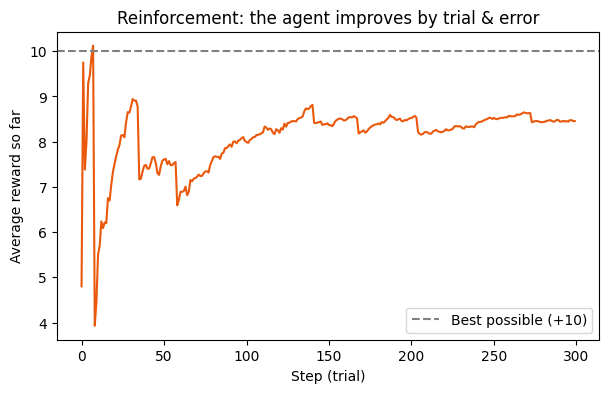

In [8]:
# Cell 2E: Reinforcement learning — a tiny trial-and-error agent
rng = np.random.default_rng(RNG_SEED)

actions = ["Stay in lane", "Drift slightly", "Swerve to curb"]
true_avg_reward = [+10, +2, -50]       # hidden from the agent!

value_estimate = np.zeros(3)           # agent's beliefs, start at zero
times_tried = np.zeros(3)
epsilon = 0.1                          # 10% of the time: explore a random action
history = []

for step in range(300):
    if rng.random() < epsilon:
        a = rng.integers(3)                      # explore
    else:
        a = int(np.argmax(value_estimate))       # exploit best-known action
    reward = true_avg_reward[a] + rng.normal(0, 5)   # environment responds (noisy)
    times_tried[a] += 1
    value_estimate[a] += (reward - value_estimate[a]) / times_tried[a]   # update belief
    history.append(reward)

for name, v, t in zip(actions, value_estimate, times_tried):
    print(f"{name:<16} learned value = {v:6.1f}   tried {int(t):3d} times")

running_avg = np.cumsum(history) / np.arange(1, len(history) + 1)
plt.plot(running_avg, color="#ea580c")
plt.axhline(10, ls="--", color="gray", label="Best possible (+10)")
plt.xlabel("Step (trial)"); plt.ylabel("Average reward so far")
plt.title("Reinforcement: the agent improves by trial & error"); plt.legend(); plt.show()

---
# Part 03: The ML Lifecycle

## 3A. The 6-Step End-to-End ML Lifecycle

| Step | Name | Kitchen analogy |
|:-:|---|---|
| 01 | **Problem Definition** | Decide what dish to cook |
| 02 | **Data Collection** | Buy the ingredients |
| 03 | **Data Cleaning (EDA)** | Wash & prep the ingredients |
| 04 | **Model Training** | Cook |
| 05 | **Model Evaluation** | Taste test |
| 06 | **Live Deployment** | Serve to customers |

> 🍳 **The MasterChef Rule — "Garbage In, Garbage Out":** in real companies, **~80% of engineering time** goes into Steps 1–3 (washing and prepping clean ingredients before cooking).

---
## Step 1 Deep Dive: Problem Framing

### How to turn a business goal into an ML problem
`"Increase our app revenue"` (vague wish) → `"Who will cancel next month?"` (specific target **y**) → **Supervised Classification** (exact ML category)

| Company goal (what the boss says) | ML problem formulation (what we predict) | ML task type |
|---|---|---|
| "Dialog/Mobitel is losing users" | Will this customer cancel within 30 days? (Yes/No) | **Classification** |
| "Keells vegetables are spoiling" | Exact kg of carrots sold tomorrow | **Regression** |
| "Send better bank card offers" | Group cardholders by monthly spending habits | **Clustering** |

### 4 reasons a business problem *needs* ML (the green lights)
1. **Rules are too complex** — impossible to write `if-else` rules for voice recognition or disease photos.
2. **Patterns keep changing** — scammers invent new tricks daily; ML adapts to new data.
3. **Massive human scale** — humans cannot check 1,000,000 card swipes per minute.
4. **Hyper-personalization** — customizing PickMe food feeds or Netflix homepages for every single user.

In [ ]:
# Cell 3A: Quick quiz — frame the problem. Fill in "Classification", "Regression" or "Clustering".
my_answers = {
    "Predict tomorrow's electricity demand in MW for Colombo": "",
    "Detect whether a card transaction is fraud (Yes/No)": "",
    "Group tea estates by soil and rainfall patterns": "",
    "Estimate a used car's resale price": "",
}

correct = {
    "Predict tomorrow's electricity demand in MW for Colombo": "Regression",
    "Detect whether a card transaction is fraud (Yes/No)": "Classification",
    "Group tea estates by soil and rainfall patterns": "Clustering",
    "Estimate a used car's resale price": "Regression",
}

for question, answer in my_answers.items():
    if not answer:
        print(f"[ ? ] {question}")
    else:
        mark = "✅" if answer.strip().lower() == correct[question].lower() else "❌"
        print(f"[{mark}] {question} -> {answer}")

### When you should NOT use Machine Learning!
1. **Clear fixed rules already exist** — EPF/ETF payroll tax, electricity bill tiers (`if units > 90`).
2. **Zero or tiny historical data** — a brand-new shop with only 15 sales rows cannot train a model.
3. **100% zero-error accuracy is required** — ATM balance deduction. ML guesses *probabilities*, not exact math.

> 💡 Great ML Engineers know when a simple 5-line Python script beats a complex AI model!

In [ ]:
# Cell 3B: A fixed-rule problem — NO ML needed.
# Tier prices below are simplified example numbers, NOT the official CEB tariff.
def monthly_electricity_bill(units: int) -> float:
    if units <= 30:
        return units * 8.0
    elif units <= 60:
        return 30 * 8.0 + (units - 30) * 20.0
    elif units <= 90:
        return 30 * 8.0 + 30 * 20.0 + (units - 60) * 30.0
    else:
        return 30 * 8.0 + 30 * 20.0 + 30 * 30.0 + (units - 90) * 50.0

for u in [25, 55, 90, 150]:
    print(f"{u:>3} units -> Rs. {monthly_electricity_bill(u):,.2f}")
print("\nExact, explainable, zero training data. Using ML here would only add errors.")

---
## Step 2 Deep Dive: Where Do We Collect Data From?

| 1. Internal company data | 2. Open public datasets | 3. Live APIs & sensors |
|---|---|---|
| SQL databases, POS supermarket bills, CRM customer logs, Excel sheets | Kaggle, Hugging Face, UCI Repository, Sri Lanka Census statistics | Weather APIs, IoT factory temperature sensors, GPS logs, web scraping (only where permitted) |

## 🔐 Data Privacy, Security & Ethical AI Rules

| Rule | What it means |
|---|---|
| **1. Remove personal identity (PII masking)** | Never feed customer names, NIC numbers, or phone numbers into a model. Replace them with an ID like `User_ID_904`. |
| **2. Legal compliance (Sri Lanka PDPA & GDPR)** | Collect only what users consented to share. **Never upload private company CSVs to public AI tools.** |
| **3. Prevent unfair algorithmic bias** | Do not use gender, religion, or race to reject bank loans or job applicants. |

### Data collection: allowed vs strictly forbidden

| ✅ GREEN ZONE — allowed & safe | ⛔ RED ZONE — illegal & unethical |
|---|---|
| Anonymized hospital & bank records (blood sugar + age to predict diabetes, with name & NIC removed) | Scraping private profiles behind logins (private Facebook photos, WhatsApp chats) |
| Public datasets & official APIs (Kaggle, Central Bank reports, public property listings) | Exposing raw credit cards, passwords or NICs in training CSVs |
| Opt-in app behavior logs (cart clicks where the user accepted the privacy terms) | Secretly recording audio or CCTV faces without legal notice |

Let's apply rules 1 and 3 in code: **RAW PII → MASK & HASH → SAFE ML DATASET**.

In [9]:
# Cell 3C-1: A raw customer table that is NOT safe to use for ML (all data is fake)
raw_customers = pd.DataFrame({
    "name":        ["Kasun Perera", "Nimali Silva", "Ruwan Fernando", "Ayesha Rahman"],
    "nic":         ["199512345678", "200034567812", "198876543210", "199923456789"],
    "phone":       ["0771234567", "0719876543", "0765554433", "0703332211"],
    "gender":      ["M", "F", "M", "F"],
    "religion":    ["Buddhist", "Catholic", "Hindu", "Muslim"],
    "age":         [28, 24, 36, 31],
    "income_k":    [120, 85, 150, 95],
    "loan_repaid": ["Yes", "No", "Yes", "Yes"],
})
raw_customers

,name,nic,phone,gender,religion,age,income_k,loan_repaid
0,Kasun Perera,199512345678,0771234567,M,Buddhist,28,120,Yes
1,Nimali Silva,200034567812,0719876543,F,Catholic,24,85,No
2,Ruwan Fernando,198876543210,0765554433,M,Hindu,36,150,Yes
3,Ayesha Rahman,199923456789,0703332211,F,Muslim,31,95,Yes


In [10]:
# Cell 3C-2: Mask & hash -> a safe ML dataset
import hashlib

# In real projects the salt is a SECRET kept outside the code (env variable / secret manager)
# and never committed to Git. A hard-coded value is used here only for teaching.
SALT = "demo-salt-change-me"

def pseudonymize(nic: str) -> str:
    """One-way salted SHA-256 hash -> short, stable user ID. The NIC cannot be read back."""
    digest = hashlib.sha256((SALT + nic).encode("utf-8")).hexdigest()
    return f"User_{digest[:8]}"

def mask_phone(phone: str) -> str:
    """Keep only what a human support agent might need: the last 3 digits."""
    return "*" * (len(phone) - 3) + phone[-3:]

safe = raw_customers.copy()
safe.insert(0, "user_id", safe["nic"].apply(pseudonymize))   # stable ID replaces identity
safe["phone_masked"] = safe["phone"].apply(mask_phone)        # for display only, never a model feature

PII_COLUMNS = ["name", "nic", "phone"]                 # Rule 1: direct identifiers
SENSITIVE_COLUMNS = ["gender", "religion"]             # Rule 3: must not drive loan decisions
safe_ml_dataset = safe.drop(columns=PII_COLUMNS + SENSITIVE_COLUMNS + ["phone_masked"])

print("Columns removed:", PII_COLUMNS + SENSITIVE_COLUMNS)
safe_ml_dataset

Columns removed: ['name', 'nic', 'phone', 'gender', 'religion']


,user_id,age,income_k,loan_repaid
0,User_c9ff3216,28,120,Yes
1,User_de363d4c,24,85,No
2,User_75898fe4,36,150,Yes
3,User_ea470a26,31,95,Yes


**Why this matters**
- The same NIC always produces the same `user_id`, so we can still join tables — but the NIC cannot be read back from the hash.
- Hashing is **pseudonymization**, not full anonymization. With the salt, someone could re-test NICs, so the salt must stay secret, and ages/incomes combined can still identify people in small datasets.
- Dropping `gender`/`religion` is a first step against bias. Other columns (e.g. home area) can still act as hidden *proxies*, which is why we always **audit model decisions per group** later in the course.
- 🚫 **Never** paste `raw_customers` into ChatGPT, Gemini, Claude or any public AI tool. Company data stays inside company systems.

---
## Step 3: Cleaning Missing Values & Outliers (EDA)

Real-world data is messy:

| Customer | Age | Income | Approved? |
|---|---|---|---|
| Kasun | 28 | Rs. 120,000 | Yes |
| Nimali | **NaN (empty!)** | Rs. 85,000 | No |
| Ruwan | **250 (outlier!)** | Rs. 150,000 | Yes |

1. **Missing values (NaN):** blank cells break math formulas. Fix by filling with the column average (or median), or by dropping the row.
2. **Outliers (extreme typos):** impossible values like `Age = 250` skew predictions. Spot them with EDA charts and remove or fix them.

In [12]:
# Cell 3D-1: A messy real-world style dataset
messy = pd.DataFrame({
    "customer": ["Kasun", "Nimali", "Ruwan", "Dilini", "Tharindu", "Sanduni", "Isuru", "Malsha"],
    "age":      [28, np.nan, 250, 34, 41, np.nan, 29, 38],
    "income":   [120_000, 85_000, 150_000, 95_000, 130_000, 70_000, 110_000, 99_000],
    "approved": ["Yes", "No", "Yes", "Yes", "Yes", "No", "Yes", "No"],
})
print("Missing values per column:")
print(messy.isna().sum())
print("\nQuick stats (look at max age!):")
print(messy["age"].describe())

Missing values per column:
customer    0
age         2
income      0
approved    0
dtype: int64

Quick stats (look at max age!):
count      6.000000
mean      70.000000
std       88.324402
min       28.000000
25%       30.250000
50%       36.000000
75%       40.250000
max      250.000000
Name: age, dtype: float64


Outlier rows:
   customer    age  income approved
2    Ruwan  250.0  150000      Yes

Filled missing ages with median = 34.0


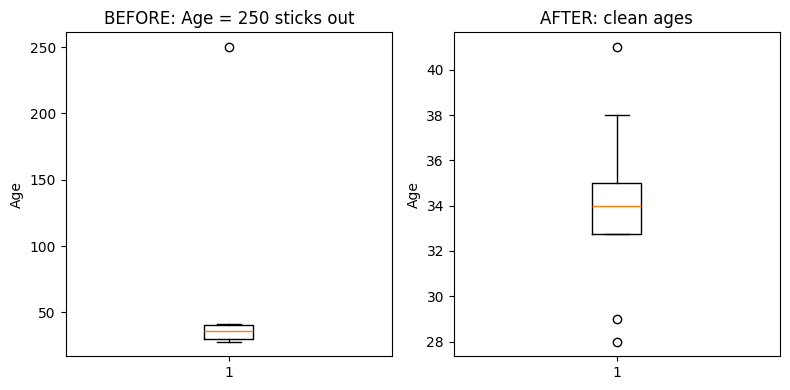

,customer,age,income,approved
0,Kasun,28.0,120000,Yes
1,Nimali,34.0,85000,No
2,Ruwan,34.0,150000,Yes
3,Dilini,34.0,95000,Yes
4,Tharindu,41.0,130000,Yes
5,Sanduni,34.0,70000,No
6,Isuru,29.0,110000,Yes
7,Malsha,38.0,99000,No


In [13]:
# Cell 3D-2: Spot the outlier with a boxplot, then fix it
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].boxplot(messy["age"].dropna())
axes[0].set_title("BEFORE: Age = 250 sticks out"); axes[0].set_ylabel("Age")

clean = messy.copy()

# 1) Outliers: use the IQR rule (values far outside the middle 50%) + a common-sense range
q1, q3 = clean["age"].quantile([0.25, 0.75])
iqr = q3 - q1
is_outlier = (clean["age"] < q1 - 1.5 * iqr) | (clean["age"] > q3 + 1.5 * iqr) | (clean["age"] > 120)
print("Outlier rows:\n", clean[is_outlier])
clean.loc[is_outlier, "age"] = np.nan      # treat the typo as unknown

# 2) Missing values: fill with the median (robust to any remaining extremes)
median_age = clean["age"].median()
clean["age"] = clean["age"].fillna(median_age)
print(f"\nFilled missing ages with median = {median_age}")

axes[1].boxplot(clean["age"])
axes[1].set_title("AFTER: clean ages"); axes[1].set_ylabel("Age")
plt.tight_layout(); plt.show()
clean

---
## Step 4: What Does "Model Training" Actually Mean?

1. **Make an initial guess** — the algorithm starts with random internal knobs (*weights*).
2. **Measure the error (loss)** — check how far its predictions are from the real answers.
3. **Adjust the knobs & repeat** — tweak the weights thousands of times until the error is tiny.

`RED = guess #1 (wrong) → GREEN = trained best fit (model.fit)`

Below we do those three steps **by hand** so you can watch a line learn. (The calculus behind "adjust" is Week 3.)

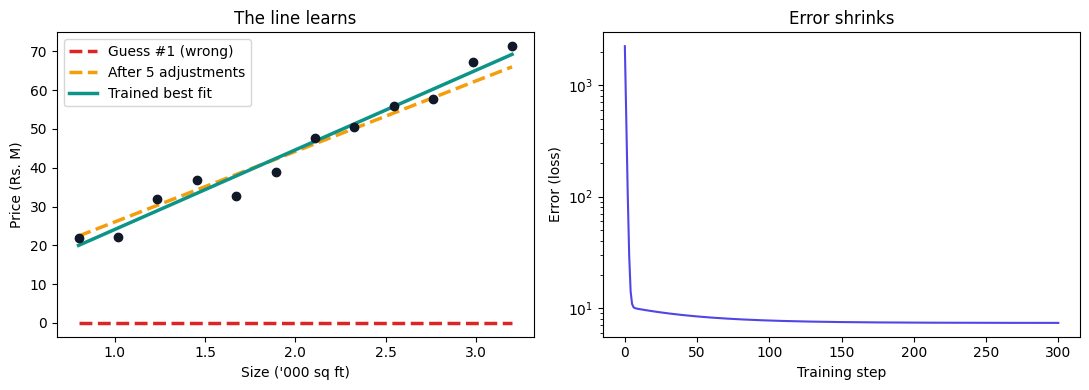

Final learned line: price = 20.5 × size + 3.6   (true: 20 × size + 5)


In [14]:
# Cell 3E: Watch a model train — guess, measure error, adjust, repeat
rng = np.random.default_rng(RNG_SEED)
x = np.linspace(0.8, 3.2, 12)                      # size in thousand sq ft
y = 20 * x + 5 + rng.normal(0, 3, x.size)         # price in Rs. million

w, b = 0.0, 0.0             # 1) initial guess: a flat line
learning_rate = 0.05
losses, snapshots = [], {}

for step in range(301):
    pred = w * x + b
    error = pred - y
    loss = np.mean(error ** 2)                     # 2) measure the error (Mean Squared Error)
    losses.append(loss)
    if step in (0, 5, 300):
        snapshots[step] = (w, b)
    w -= learning_rate * 2 * np.mean(error * x)    # 3) adjust the knobs a little...
    b -= learning_rate * 2 * np.mean(error)        #    ...and repeat

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, y, color="#111827", zorder=3)
styles = {0: ("#dc2626", "--", "Guess #1 (wrong)"), 5: ("#f59e0b", "--", "After 5 adjustments"),
          300: ("#0d9488", "-", "Trained best fit")}
for s, (ws, bs) in snapshots.items():
    color, ls, label = styles[s]
    axes[0].plot(x, ws * x + bs, color=color, ls=ls, lw=2.5, label=label)
axes[0].set_xlabel("Size ('000 sq ft)"); axes[0].set_ylabel("Price (Rs. M)"); axes[0].legend()
axes[0].set_title("The line learns")
axes[1].plot(losses, color="#4f46e5"); axes[1].set_yscale("log")
axes[1].set_xlabel("Training step"); axes[1].set_ylabel("Error (loss)"); axes[1].set_title("Error shrinks")
plt.tight_layout(); plt.show()
print(f"Final learned line: price = {w:.1f} × size + {b:.1f}   (true: 20 × size + 5)")

---
## Step 5: Evaluation & The School Exam Analogy

Before training, split the historical rows (e.g. 10,000):

| 80% Training set (8,000 rows) | 20% Test set (2,000 rows) |
|---|---|
| Like homework practice questions used to study patterns | 🔒 Locked, unseen final exam! |

- **Overfitting (memorizing):** a student who memorizes past papers scores 100% at home but fails when given new questions.
- **Why the unseen test matters:** testing on hidden data proves our model genuinely works in the real world.

In [15]:
# Cell 3F: 80/20 split + an overfitting demo
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_demo, y_demo = make_moons(n_samples=10_000, noise=0.45, random_state=RNG_SEED)
X_train, X_test, y_train, y_test = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=RNG_SEED)
print(f"Training rows: {len(X_train):,}  |  Test rows (locked exam): {len(X_test):,}\n")

memorizer = DecisionTreeClassifier(random_state=RNG_SEED)                 # no limits -> memorizes
learner = DecisionTreeClassifier(max_depth=5, random_state=RNG_SEED)     # forced to keep it simple

print(f"{'Model':<28}{'Homework (train)':>18}{'Final exam (test)':>20}")
for name, model in [("Memorizer (unlimited depth)", memorizer), ("Learner (max_depth=5)", learner)]:
    model.fit(X_train, y_train)
    print(f"{name:<28}{model.score(X_train, y_train):>17.1%}{model.score(X_test, y_test):>19.1%}")

Training rows: 8,000  |  Test rows (locked exam): 2,000

Model                         Homework (train)   Final exam (test)
Memorizer (unlimited depth)            100.0%              78.7%
Learner (max_depth=5)                   83.8%              83.7%


The **memorizer** scores ~100% on homework but drops on the unseen exam — that gap is **overfitting**.
The simpler **learner** scores lower at home but *better* on the exam. We always judge a model on the **test set**.

---
## Step 6: Taking Models Out of Notebooks (Deployment)

```
1. User web / mobile app   ⇄   2. FastAPI / Streamlit server   ⇄   3. Trained ML model (model.pkl)
   "3 beds, 2000 sqft,           receives the request and           calculates and returns
    Colombo"                     passes inputs to the model         "Rs. 45 Million" in ~50 ms
```

> A model sitting inside a laptop notebook helps nobody — **deployment turns your math into a real product!**

Step one of deployment is **saving** the trained model to a file, so a server can **load** it later without retraining.

In [16]:
# Cell 3G: Save the trained house-price model, then load it like a server would
import joblib
from pathlib import Path

model_path = Path("house_price_model.pkl")      # *.pkl files are git-ignored in this repo
joblib.dump(reg, model_path)
print(f"Saved model -> {model_path.resolve()}")

# ... later, inside the web server ...
loaded_model = joblib.load(model_path)
request = [[2000]]                               # a user asks about a 2,000 sqft house
print(f"Server response: Rs. {loaded_model.predict(request)[0]:.1f} Million")

Saved model -> /Users/adithyabandara/ML-2/week1/house_price_model.pkl
Server response: Rs. 45.3 Million


A minimal **Streamlit** app that serves this model (save as `app.py`, run with `streamlit run app.py`).
Don't run it inside the notebook — we build real apps in Month 3.

```python
import joblib
import streamlit as st

model = joblib.load("house_price_model.pkl")

st.title("🏠 Colombo House Price Predictor")
size = st.number_input("House size (sq ft)", min_value=300, max_value=10_000, value=2000)

if st.button("Predict"):
    price = model.predict([[size]])[0]
    st.success(f"Estimated price: Rs. {price:.1f} Million")
```

> 🔐 Security note: only `joblib.load` / `pickle.load` files **you created or fully trust** — loading a pickle can run arbitrary code.

---
# Part 04: Data Basics

## 4A. How Machines View Data: Features (X) vs Target (y)

- **Row = Sample** (one house, one customer, one email).
- **Features (X) = independent variables** — the input clues.
- **Target (y) = output label** — the answer we want to predict.

| Row (sample) | Size (sq ft) | Bedrooms | Distance to city | **Price (target y)** |
|---|---|---|---|---|
| House #1 | 2,000 | 3 | 5 km | **45 Million** |
| House #2 | 1,200 | 2 | 18 km | **22 Million** |
| House #3 | 3,100 | 5 | 2 km | **80 Million** |

In [17]:
# Cell 4A: Splitting a table into X (features) and y (target)
houses = pd.DataFrame({
    "size_sqft":   [2000, 1200, 3100],
    "bedrooms":    [3, 2, 5],
    "distance_km": [5, 18, 2],
    "price_m":     [45, 22, 80],
}, index=["House #1", "House #2", "House #3"])

feature_columns = ["size_sqft", "bedrooms", "distance_km"]
target_column = "price_m"

X = houses[feature_columns]     # 2D table  -> shape (n_samples, n_features)
y = houses[target_column]       # 1D column -> shape (n_samples,)

print("X shape:", X.shape, "-> 3 samples, 3 features")
print("y shape:", y.shape, "-> 3 answers\n")
display(X)
display(y.to_frame())

X shape: (3, 3) -> 3 samples, 3 features
y shape: (3,) -> 3 answers



,size_sqft,bedrooms,distance_km
House #1,2000,3,5
House #2,1200,2,18
House #3,3100,5,2


,price_m
House #1,45
House #2,22
House #3,80


## 4B. Two Flavors of Data: Structured vs Unstructured

| | Structured (tabular) — *Months 1 & 2: classical ML* | Unstructured — *Month 3: deep learning* |
|---|---|---|
| **Format** | Neat rows & columns in tables | Raw pixels, sound waves, and text |
| **Examples** | Excel files, CSVs, SQL bank records | Tea leaf photos, voice notes, PDFs, chats |
| **Algorithms** | Linear Regression, Random Forest, XGBoost | Neural Networks, CNNs & LLMs |

Key idea: **to a computer, even a photo is just a grid of numbers.**

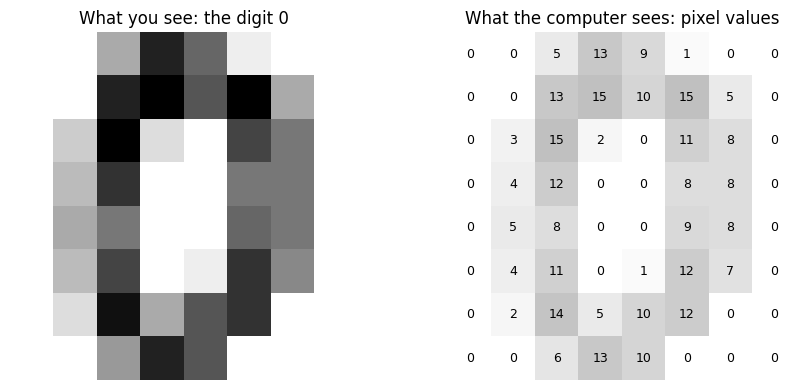

Image shape: (8, 8) -> 64 numbers per picture


In [18]:
# Cell 4B: An image is just numbers
from sklearn.datasets import load_digits

digits = load_digits()            # small handwritten-digit images bundled with scikit-learn
image = digits.images[0]          # one 8x8 grayscale picture

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(image, cmap="gray_r"); axes[0].set_title(f"What you see: the digit {digits.target[0]}")
axes[0].axis("off")
axes[1].imshow(image, cmap="gray_r", alpha=0.25)
for (r, c), v in np.ndenumerate(image):
    axes[1].text(c, r, int(v), ha="center", va="center", fontsize=9)
axes[1].set_title("What the computer sees: pixel values"); axes[1].axis("off")
plt.tight_layout(); plt.show()

print("Image shape:", image.shape, "->", image.size, "numbers per picture")

---
# Part 05: Python Environment Setup & Week 2 Checklist

| | ☁️ **Option A — Google Colab** (easiest start) | 💻 **Option B — Conda + Jupyter** (offline laptop) | 🐍 **Option C — venv** (no Conda) |
|---|---|---|---|
| Install | Zero install, works in the browser | [Miniconda](https://www.anaconda.com/download/success) (or [Miniforge](https://github.com/conda-forge/miniforge)) | Python 3.10–3.12 from [python.org](https://www.python.org/downloads/) |
| Hardware | Free cloud GPUs | Your laptop | Your laptop |
| Action | Log in at [colab.research.google.com](https://colab.research.google.com) | `conda env create -f environment.yml`<br>`conda activate ml-course`<br>`jupyter lab` | `python3.12 -m venv .venv`<br>`source .venv/bin/activate`<br>`pip install -r requirements.txt` |

### ✅ Week 2 checklist
- [ ] Colab account works **or** the `ml-course` environment is installed
- [ ] Cell 0 of this notebook runs without errors
- [ ] You can run `print("Hello ML!")` in a fresh notebook
- [ ] VS Code + Python & Jupyter extensions installed (optional but recommended)
- [ ] A free [Kaggle](https://www.kaggle.com) account for datasets

In [ ]:
# Cell 5: Your first line of ML-course Python
print("Hello ML!")

---
# ✍️ Week 1 Exercises

Try each task yourself first. Solutions are at the bottom — no peeking!

1. **Problem framing.** For the goal *"Reduce hospital waiting times"*, write one specific prediction (target **y**) and its ML task type.
2. **ML or if-else?** For each case, decide `"ML"` or `"RULES"`: (a) calculating a 15% VAT, (b) recognizing a cat in a photo, (c) a new café with 10 days of sales wanting to forecast demand.
3. **PII masking.** In `students` below, replace `nic` with a pseudonymous `student_id` (reuse `pseudonymize`) and drop every direct identifier.
4. **Cleaning.** In the same table, fix the impossible `marks` value (marks must be 0–100) and fill missing marks with the median.
5. **X / y split.** Use `hours_studied` and `attendance_pct` as features and `marks` as the target, then do an 80/20 `train_test_split` with `random_state=42`. Print all four shapes.

In [ ]:
# Exercise data (all fake)
students = pd.DataFrame({
    "full_name":      ["A. Bandara", "K. Jayasuriya", "M. Peiris", "S. Kumar", "R. Nawaz",
                       "D. Wickrama", "P. Gunasekara", "T. Herath", "N. Rajapaksha", "L. Mendis"],
    "nic":            ["200112345678", "200223456789", "200134567890", "200245678901", "200156789012",
                       "200267890123", "200178901234", "200289012345", "200190123456", "200201234567"],
    "email":          [f"student{i}@example.com" for i in range(10)],
    "hours_studied":  [10, 4, 7, 12, 3, 8, 6, 11, 5, 9],
    "attendance_pct": [95, 60, 80, 98, 55, 85, 75, 92, 70, 88],
    "marks":          [88, 45, np.nan, 93, 380, 76, 64, np.nan, 52, 81],
})

# --- Your answers here ---
# 1. ...
# 2. ...
# 3. ...
# 4. ...
# 5. ...

### 🔑 Solutions

In [ ]:
# Solutions 1 & 2 (written answers)
solution_1 = "Predict each patient's waiting time in minutes at arrival -> Regression"
solution_2 = {"(a) 15% VAT": "RULES", "(b) cat in a photo": "ML", "(c) café with 10 days of data": "RULES"}
print(solution_1)
print(solution_2)

# Solution 3: pseudonymize + drop direct identifiers
students_safe = students.copy()
students_safe.insert(0, "student_id", students_safe["nic"].apply(pseudonymize))
students_safe = students_safe.drop(columns=["full_name", "nic", "email"])

# Solution 4: impossible marks -> NaN, then median fill
students_safe.loc[~students_safe["marks"].between(0, 100), "marks"] = np.nan
students_safe["marks"] = students_safe["marks"].fillna(students_safe["marks"].median())
display(students_safe)

# Solution 5: X / y + 80/20 split
X_s = students_safe[["hours_studied", "attendance_pct"]]
y_s = students_safe["marks"]
X_s_train, X_s_test, y_s_train, y_s_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)
print("X_train:", X_s_train.shape, "| X_test:", X_s_test.shape,
      "| y_train:", y_s_train.shape, "| y_test:", y_s_test.shape)

---
# 📎 Appendix (Bonus): Data as NumPy Arrays — Tensors, Slicing & Vectorization

*Optional preview of Week 2.* This section goes one level deeper into **how** tables become arrays of numbers.

## A1. The Geometric Hierarchy of Data

In Machine Learning, all unstructured and structured data must be represented numerically as Tensors (multidimensional arrays):
- **Scalar ($0\text{D}$ Tensor):** A single number with magnitude only (rank 0).
- **Vector ($1\text{D}$ Tensor):** An ordered list of numbers representing either one sample across $d$ features or one feature across $n$ samples (rank 1).
- **Matrix ($2\text{D}$ Tensor):** A tabular grid of shape $(n, d)$ where $n = \text{samples}$ and $d = \text{features}$ (rank 2).
- **3D+ Tensor:** Multidimensional arrays representing color images $(H, W, C)$ or batches of sequences $(B, T, D)$.

In [ ]:
# Cell A1: Creating and Inspecting Tensors

# 1. Scalar (0D)
scalar = np.array(42)

# 2. Vector (1D) - e.g., A single customer's [Age, Income, Credit Score]
vector = np.array([32, 65000.0, 710])

# 3. Matrix (2D) - e.g., 4 customers with 3 features each
matrix = np.array([
    [25, 45000.0, 680],
    [38, 82000.0, 740],
    [45, 110000.0, 790],
    [22, 28000.0, 610]
])

# 4. 3D Tensor - e.g., 2 RGB images of size 2x2 pixels
tensor_3d = np.zeros((2, 2, 3))

# Displaying structural attributes
tensors = [("Scalar", scalar), ("Vector", vector), ("Matrix", matrix), ("3D Tensor", tensor_3d)]
print(f"{'Type':<12} | {'Shape':<12} | {'Dimensions (Rank)':<18} | {'Dtype'}")
print("-" * 55)
for name, t in tensors:
    print(f"{name:<12} | {str(t.shape):<12} | {t.ndim:<18} | {t.dtype}")

## A2. Matrix Slicing & The ML Dataset Paradigm ($\mathbf{X}$ and $\mathbf{y}$)

A standard supervised tabular dataset is denoted as $\mathbf{D} = \{(\mathbf{x}^{(i)}, y^{(i)})\}_{i=1}^n$:
- $\mathbf{X} \in \mathbb{R}^{n \times d}$: The Feature Matrix containing all input predictors.
- $\mathbf{y} \in \mathbb{R}^n$: The Target Vector containing the ground truth values to predict.

### Matrix Indexing Rules:
- `array[row_index, col_index]`
- Use `:` to extract an entire row or column.
- `start:stop` slices from index start up to (but not including) stop.

In [ ]:
# Cell A2: Slicing Datasets into Features (X) and Labels (y)

# Synthetic real-estate dataset:
# Columns: [Square Feet, Bedrooms, Age of House, Price ($)]
dataset = np.array([
    [1500, 3, 10, 350000],
    [2200, 4, 5, 480000],
    [1000, 2, 20, 210000],
    [1800, 3, 15, 390000],
    [2800, 4, 2, 620000],
    [1200, 2, 30, 195000]
])

print(f"Complete Raw Dataset Shape: {dataset.shape}")

# Slicing: All rows, columns 0 through 2 (Features)
X_np = dataset[:, 0:3]

# Slicing: All rows, column index 3 only (Target)
y_np = dataset[:, 3]

print("\n--- Feature Matrix (X) ---")
print(f"Shape: {X_np.shape}")
print(X_np)

print("\n--- Target Vector (y) ---")
print(f"Shape: {y_np.shape}")
print(y_np)

# Boolean Indexing: Filter houses with more than 2 bedrooms
bedroom_mask = X_np[:, 1] > 2
print("\nHouses with > 2 bedrooms (Filtered X):")
print(X_np[bedroom_mask])

## A3. Dimensionality Transformations & Reshaping

A frequent source of errors in machine learning libraries (like Scikit-Learn and PyTorch) is passing a 1D vector of shape `(n,)` where a 2D column vector of shape `(n, 1)` is required.
- A vector with shape `(n,)` is flat (rank 1).
- A vector with shape `(n, 1)` is an explicit 2D matrix with $n$ rows and 1 column.

In [ ]:
# Cell A3: Reshaping and Dimension Expansion

# Inspect current target vector shape
print(f"Original y shape: {y_np.shape} (Rank {y_np.ndim})")

# Method 1: Using .reshape() with -1 (dimension inferred automatically)
y_col_vector = y_np.reshape(-1, 1)
print(f"Reshaped y shape: {y_col_vector.shape} (Rank {y_col_vector.ndim})")

# Method 2: Using np.newaxis
y_col_newaxis = y_np[:, np.newaxis]
print(f"np.newaxis y shape: {y_col_newaxis.shape}")

# Method 3: Flattening a 2D matrix back to a 1D vector
y_flat = y_col_vector.flatten()
print(f"Flattened back: {y_flat.shape}")

## A4. Vectorization vs. Standard Python Loops

Machine learning models iterate over millions of parameters. Python `for` loops are slow because of dynamic type checking and memory overhead.

NumPy uses SIMD (Single Instruction, Multiple Data) and pre-compiled C code under the hood. This optimization is called **Vectorization**.

In [ ]:
# Cell A4: Benchmark - Vectorized Operations vs. Python Loops
import time

# Create two vectors with 2,000,000 elements
N = 2_000_000
a = np.random.rand(N)
b = np.random.rand(N)

# 1. Native Python Loop Dot Product
start_time = time.time()
dot_product_loop = 0.0
for i in range(N):
    dot_product_loop += a[i] * b[i]
loop_duration = time.time() - start_time

# 2. NumPy Vectorized Dot Product
start_time = time.time()
dot_product_vectorized = np.dot(a, b)
vectorized_duration = time.time() - start_time

# Benchmark Results
print(f"Loop Duration: {loop_duration:.5f} seconds")
print(f"Vectorized Duration: {vectorized_duration:.5f} seconds")
print(f"Speedup Factor: {loop_duration / vectorized_duration:.1f}x faster")

np.testing.assert_allclose(dot_product_loop, dot_product_vectorized, rtol=1e-9)
print("Results match!")

## A5. Bonus Exercise (NumPy)

Complete the tasks below using only NumPy functions. Do not use standard Python loops (`for` or `while`).

1. **Dataset Generation:** Generate a synthetic matrix `grades` containing 100 students and 5 exam scores. Use random integers between 40 and 100 (`np.random.randint`). Fix the random seed to 42 for reproducibility.
2. **Matrix Partitioning:** Separate `grades` into:
   - Feature Matrix `X_grades`: All students, the first 4 exams.
   - Target Vector `y_grades`: All students, the 5th final exam.
3. **Reshaping:** Reshape `y_grades` into a 2D column vector of shape `(100, 1)`.
4. **Summary Statistics:**
   - Calculate the average score for each exam across all students (column-wise mean).
   - Calculate the average score for each student across the 4 practice exams (row-wise mean).
5. **High-Performer Filtering:** Extract only the rows in `X_grades` where the student's average across the 4 practice exams is $\ge 75$.

In [ ]:
# Cell A5: Bonus exercise solution

# --- Task 1: Generate Dataset ---
np.random.seed(42)
grades = np.random.randint(40, 101, size=(100, 5))

# --- Task 2: Separate X and y ---
X_grades = grades[:, :4]
y_grades = grades[:, 4]

# --- Task 3: Reshape y into (100, 1) ---
y_grades_col = y_grades.reshape(-1, 1)

# --- Task 4: Summary Statistics ---
# Column-wise mean: axis=0 collapses rows, computing mean per exam
exam_means = np.mean(grades, axis=0)

# Row-wise mean for first 4 exams: axis=1 collapses columns, computing mean per student
student_means = np.mean(X_grades, axis=1)

# --- Task 5: High-Performer Filtering ---
high_performer_mask = student_means >= 75
X_high_performers = X_grades[high_performer_mask]

# --- Verification Outputs ---
print("Shape of X_grades: ", X_grades.shape)
print("Shape of y_grades_col: ", y_grades_col.shape)
print("Exam Means (Exams 1 to 5):", np.round(exam_means, 2))
print(f"Total High Performers (>= 75 avg): {X_high_performers.shape[0]} students")
print("First 3 High Performers:\n", X_high_performers[:3])

---
## 🎉 Week 1 Complete — Questions & Discussion

Have your Google Colab account or Conda environment ready — **next week we write real Python for linear algebra!**
➡️ [Week 02: Linear Algebra for Machine Learning](../week2/Week_02_Linear_Algebra_for_Machine_Learning.ipynb)